# Dezvoltare software analiza date
## Seminar 4 - Analiza în componente principale (ACP) de la zero

Fie $X \in \mathbb{R}^{n \times m}$ matricea datelor, cu $n$ observații (țări) pe linii și $m$ variabile (haplogrupe) pe coloane; $x_{ij}$ este valoarea variabilei $j$ pentru observația $i$.

Implementăm ACP doar cu `numpy`, în pașii:

1. **Standardizarea datelor.** Pentru fiecare variabilă $j = 1, \dots, m$:
$$\bar{x}_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad \sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n} \left(x_{ij} - \bar{x}_j\right)^2}, \qquad z_{ij} = \frac{x_{ij} - \bar{x}_j}{\sigma_j}$$
Rezultă $Z \in \mathbb{R}^{n \times m}$, cu fiecare coloană de medie $0$ și abatere standard $1$.

2. **Matricea de corelație** dintre variabile:
$$R = \frac{1}{n} Z^T Z \in \mathbb{R}^{m \times m}, \qquad r_{jk} = \frac{1}{n}\sum_{i=1}^{n} z_{ij}\, z_{ik} = \operatorname{corr}(x_j, x_k)$$
$R$ este simetrică, pozitiv semidefinită, cu $r_{jj} = 1$.

3. **Valorile și vectorii proprii** ai lui $R$:
$$R\, a_k = \alpha_k\, a_k, \qquad \alpha_1 \ge \alpha_2 \ge \dots \ge \alpha_m \ge 0, \qquad a_k^T a_l = \delta_{kl}$$
Notăm $A = [a_1 \mid a_2 \mid \dots \mid a_m] \in \mathbb{R}^{m \times m}$ (ortogonală). Deoarece $\sum_{k=1}^{m} \alpha_k = \operatorname{tr}(R) = m$, componenta $k$ explică o proporție $\frac{\alpha_k}{m}$ din varianța totală.

4. **Componentele principale** (scorurile observațiilor):
$$C = Z A \in \mathbb{R}^{n \times m}, \qquad c_k = Z a_k, \qquad \operatorname{Var}(c_k) = \alpha_k$$

5. **Corelațiile factoriale** dintre variabila $x_j$ și componenta $c_k$:
$$r_{x_j, c_k} = a_{jk}\sqrt{\alpha_k}$$

6. **Indicatori de calitate**, pentru primele $s$ componente păstrate:
   - comunalități: $h_j^2 = \sum_{k=1}^{s} r_{x_j, c_k}^2$, partea din varianța lui $x_j$ explicată de cele $s$ componente;
   - cosinusuri: $\cos^2_{ik} = \dfrac{c_{ik}^2}{\sum_{l=1}^{m} c_{il}^2}$, calitatea reprezentării observației $i$ pe componenta $k$;
   - contribuții: $\operatorname{ctr}_{ik} = \dfrac{c_{ik}^2}{n\,\alpha_k}$, ponderea observației $i$ în varianța componentei $k$ ($\sum_{i} \operatorname{ctr}_{ik} = 1$).

La final comparăm rezultatele cu `sklearn.decomposition.PCA`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import nan_replace_df, plot_variance, plot_correlation_circle, plot_observations, plot_corr_heatmap

### Citirea datelor
Păstrăm doar coloanele numerice (haplogrupele), fără `Country`. Valorile lipsă se înlocuiesc cu media coloanei (`nan_replace_df` din `utils.py`).

In [2]:
dna_df = pd.read_csv('./data_in/ADN/Y_DNA_Tari.csv', index_col="Code")
dna_numeric_df = dna_df.select_dtypes(include="number")

dna_df_clean = nan_replace_df(dna_numeric_df)
print("Valori lipsa:", dna_df_clean.isna().sum().sum())
n, m = dna_df_clean.shape
print("n =", n, "observatii, m =", m, "variabile")
dna_df_clean.head()

Valori lipsa: 0
n = 39 observatii, m = 12 variabile


,I1,I2a,I2b,R1a,R1b,G,J2,J1,E1b1b,T,Q,N
Code,,,,,,,,,,,,
ALB,2.0,12.0,1.5,9.0,16.0,1.5,19.5,2.0,27.5,1.0,0.0,0.0
AUT,12.0,7.0,2.5,19.0,32.0,7.5,9.0,1.0,8.0,1.0,0.5,0.5
BLR,5.5,17.5,1.0,51.0,5.5,1.5,2.5,1.0,4.0,0.0,0.0,10.0
BEL,12.0,3.0,4.5,4.0,61.0,4.0,4.0,1.0,5.0,1.0,0.5,0.0
BIH,3.0,55.5,0.0,15.0,3.5,1.5,4.0,0.5,12.0,1.0,2.0,2.0


## 1. Standardizarea datelor

Standardizarea este un procedeu de tip *feature scaling* prin care aducem fiecare variabilă la medie $0$ și abatere standard $1$:
$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{\sigma_j}, \qquad \bar{x}_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad \sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n} \left(x_{ij} - \bar{x}_j\right)^2}$$
Folosim $\frac{1}{n}$ (`ddof=0`), consecvent cu $R = \frac{1}{n} Z^T Z$.

**Exercițiu:** completați funcția `standardize`. *Atenție:* `DataFrame.std()` folosește implicit `ddof=1`.

In [12]:
def standardize(X: pd.DataFrame):
    # TODO: scadeti media fiecarei coloane si impartiti la abaterea standard (ddof=0)
    X_=X.copy()
    return (X_ - X_.mean()) /X_.std(ddof=0)
    pass

dna_std_df = standardize(dna_df_clean)
print("----------------")
print("mean: ", dna_std_df.mean().round(2))
print("----------------")
print("std: ",dna_std_df.std().round(2))

----------------
mean:  I1       0.0
I2a      0.0
I2b      0.0
R1a     -0.0
R1b     -0.0
G       -0.0
J2       0.0
J1      -0.0
E1b1b   -0.0
T       -0.0
Q       -0.0
N        0.0
dtype: float64
----------------
std:  I1       1.01
I2a      1.01
I2b      1.01
R1a      1.01
R1b      1.01
G        1.01
J2       1.01
J1       1.01
E1b1b    1.01
T        1.01
Q        1.01
N        1.01
dtype: float64


In [ ]:
# Verificare
print("Medii == 0:", np.allclose(dna_std_df.mean(), 0))
print("Abateri standard == 1:", np.allclose(dna_std_df.std(ddof=0), 1))

## 2. Matricea de corelație și descompunerea în valori proprii

Pornind de la datele standardizate $Z$, calculăm matricea de corelație a variabilelor:
$$R = \frac{1}{n} Z^T Z \in \mathbb{R}^{m \times m}$$

Deoarece $R$ este simetrică, ea se poate descompune sub forma
$$R = A \Lambda A^T,$$
unde:
- $\Lambda = \operatorname{diag}(\alpha_1, \dots, \alpha_m)$ conține valorile proprii, în ordine descrescătoare: $\alpha_1 \ge \dots \ge \alpha_m$;
- coloanele $a_k$ ale matricei $A$ sunt vectorii proprii corespunzători: $R a_k = \alpha_k a_k$.

**Exercițiu:** completați funcția `acp`.
- produsul matriceal: operatorul `@`;
- `np.linalg.eigh` (pentru matrici simetrice) returnează valorile proprii în ordine **crescătoare** — trebuie sortate descrescător, iar coloanele vectorilor proprii rearanjate în aceeași ordine (`np.argsort`).

*Întrebare:* de ce `eigh` și nu `eig`?

order: [11 10  9  8  7  6  5  4  3  2  1  0]


<Axes: >

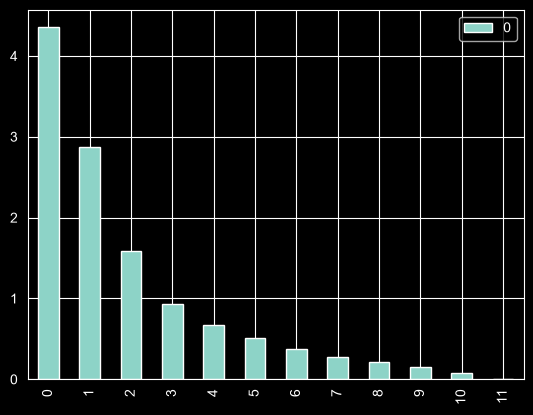

In [17]:
def acp(X: pd.DataFrame):
    """ACP pe date standardizate: matricea de corelatie si componentele sale proprii, ordonate descrescator."""
    n = X.shape[0]
    # TODO 1: matricea de corelatie R = Z^T Z / n
    correlation = (X.T @ X)/n

    # TODO 2: valorile si vectorii proprii ai lui R (np.linalg.eigh)
    eigenvalues, eigenvectors = np.linalg.eigh(correlation)

    # TODO 3: ordinea descrescatoare a valorilor proprii (np.argsort)
    order = np.argsort(eigenvalues,descending=True)

    #eigenvalues, eigenvectors -valori,vectori proprii
    #order ne da index
    print('order:', order)
    return correlation, eigenvalues[order], eigenvectors[:, order]
    #return correlation, eigenvalues[order], eigenvectors[:, order]

correlation, eigenvalues, eigenvectors = acp(dna_std_df)
pd.DataFrame(eigenvalues.round(3)).plot(kind="bar")

In [ ]:
# Verificare
print("R == np.corrcoef:", np.allclose(correlation, np.corrcoef(dna_df_clean.values, rowvar=False)))
print("Valori proprii descrescatoare:", np.all(np.diff(eigenvalues) <= 0))
print("R a_k == alpha_k a_k:", np.allclose(correlation.values @ eigenvectors, eigenvectors * eigenvalues))
print("A ortogonala:", np.allclose(eigenvectors.T @ eigenvectors, np.eye(m)))
print("Suma valorilor proprii == m:", np.isclose(eigenvalues.sum(), m))

In [ ]:
plot_corr_heatmap(correlation, title="Matricea de corelatie R")

## 3. Varianța explicată de componente

Componenta $k$ are varianța $\alpha_k$ și explică o proporție $\frac{\alpha_k}{m}$ din varianța totală.

**Exercițiu:** construiți tabelul varianței, cu câte o linie pentru fiecare componentă (`c1`, `c2`, ...) și coloanele `Varianta`, `Varianta cumulata`, `Procent varianta`, `Procent cumulat` (`np.cumsum`).

In [ ]:
def explain_variance(eigenvalues: np.ndarray):
    # TODO: procentul de varianta explicat de fiecare componenta
    procente = None
    t = pd.DataFrame(
        {
            # TODO: cele 4 coloane
        }, index=["c"+str(i+1) for i in range(len(eigenvalues))]
    )
    t.index.name = "Componenta"
    return t

explain_variance(eigenvalues)

In [ ]:
plot_variance(eigenvalues)

### Numărul de componente semnificative
Criteriul Kaiser: păstrăm componentele cu $\alpha_k > 1$, adică cele care explică mai multă varianță decât o variabilă standardizată.

**Exercițiu:** calculați `s`, numărul de componente care respectă criteriul Kaiser.

*Întrebare:* ce procent din varianța totală explică aceste $s$ componente? Uitați-vă la ultima valoare proprie: de ce este aproape $0$? (indiciu: ce reprezintă suma valorilor de pe o linie?)

In [ ]:
s = None  # TODO
print("Numar componente semnificative (Kaiser):", s)

## 4. Componentele principale
Scorurile observațiilor în noul spațiu:
$$C = Z A, \qquad c_k = Z a_k, \qquad \operatorname{Var}(c_k) = \alpha_k$$

**Exercițiu:** calculați matricea $C$ și returnați-o ca `DataFrame` cu indexul observațiilor și coloanele `C1`, `C2`, ...

In [ ]:
def principal_components(Z: pd.DataFrame, eigenvectors: np.ndarray):
    # TODO: C = Z A
    C = None
    return pd.DataFrame(C, index=Z.index, columns=["C"+str(i+1) for i in range(C.shape[1])])

components = principal_components(dna_std_df, eigenvectors)
components.head()

In [ ]:
# Verificare
print("Medii == 0:", np.allclose(components.mean(), 0))
print("Var(c_k) == alpha_k:", np.allclose(components.var(ddof=0), eigenvalues))
print("Componente necorelate:", np.allclose(np.cov(components.values, rowvar=False, ddof=0), np.diag(eigenvalues)))

### Țările în spațiul primelor două componente
*Întrebare:* ce grupuri de țări observați? Corespund ele unor regiuni geografice?

In [ ]:
plot_observations(components, dna_df["Country"], "C1", "C2")

## 5. Corelațiile factoriale
Corelația dintre variabila $x_j$ și componenta $c_k$:
$$r_{x_j, c_k} = a_{jk}\sqrt{\alpha_k}$$

**Exercițiu:** calculați matricea corelațiilor factoriale (fără buclă — folosiți *broadcasting*).

In [ ]:
def factor_correlations(eigenvalues: np.ndarray, eigenvectors: np.ndarray, variables):
    # TODO: r_xc[j, k] = a_jk * sqrt(alpha_k)
    r_xc = None
    return pd.DataFrame(r_xc, index=variables, columns=["C"+str(i+1) for i in range(len(eigenvalues))])

r_xc_df = factor_correlations(eigenvalues, eigenvectors, dna_std_df.columns)
r_xc_df.round(3)

In [ ]:
# Verificare: comparam cu corelatia calculata direct intre x_j si c_k (pentru primele s componente)
direct = np.corrcoef(dna_std_df.values, components.values[:, :s], rowvar=False)[:m, m:]
print("r_xc == corr(x_j, c_k):", np.allclose(r_xc_df.values[:, :s], direct))

In [ ]:
plot_corr_heatmap(r_xc_df, title="Corelatii factoriale")

### Cercul corelațiilor
Fiecare variabilă este un punct $(r_{x_j, c_{k_1}}, r_{x_j, c_{k_2}})$. Cu cât punctul este mai aproape de cerc, cu atât variabila este mai bine reprezentată de cele două componente.

*Întrebare:* ce haplogrupe definesc componenta `C1`? Dar `C2`? Comparați cu plotul țărilor de mai sus.

In [ ]:
plot_correlation_circle(r_xc_df, "C1", "C2")

## 6. Indicatori de calitate

### Comunalități
Partea din varianța lui $x_j$ explicată de primele $k$ componente, $k = 1, \dots, s$:
$$h_j^2 = \sum_{k=1}^{s} r_{x_j, c_k}^2$$
Valorile sunt cumulate pe coloane, deci ultima coloană este comunalitatea pentru cele $s$ componente păstrate.

**Exercițiu:** completați funcția `communalities` (`cumsum` pe linii).

In [ ]:
def communalities(r_xc: pd.DataFrame, s: int):
    # TODO: suma cumulata a patratelor corelatiilor factoriale, pentru primele s componente
    pass

communalities_df = communalities(r_xc_df, s)
communalities_df.round(3)

In [ ]:
# Verificare: cu toate cele m componente, fiecare variabila este explicata complet
print("Comunalitati cu m componente == 1:", np.allclose(communalities(r_xc_df, m).iloc[:, -1], 1))

In [ ]:
plot_corr_heatmap(communalities_df, title="Comunalitati", cmap="Blues", vmin=0, vmax=1)

### Cosinusuri
Calitatea reprezentării observației $i$ pe componenta $k$:
$$\cos^2_{ik} = \frac{c_{ik}^2}{\sum_{l=1}^{m} c_{il}^2}$$
Pe fiecare linie, cosinusurile însumează $1$.

**Exercițiu:** completați funcția `cosines` (atenție la `axis` în `DataFrame.div`).

In [ ]:
def cosines(C: pd.DataFrame):
    # TODO
    pass

cosines_df = cosines(components)
cosines_df.iloc[:, :s].round(3)

In [ ]:
# Verificare
print("Suma pe linii == 1:", np.allclose(cosines_df.sum(axis=1), 1))

### Contribuții
Ponderea observației $i$ în varianța componentei $k$:
$$\operatorname{ctr}_{ik} = \frac{c_{ik}^2}{n\,\alpha_k}$$
Pe fiecare coloană, contribuțiile însumează $1$.

**Exercițiu:** completați funcția `contributions`.

*Întrebare:* care sunt țările cu cea mai mare contribuție la `C1`? (`idxmax`, `nlargest`)

In [ ]:
def contributions(C: pd.DataFrame, eigenvalues: np.ndarray):
    # TODO
    pass

contributions_df = contributions(components, eigenvalues)
contributions_df.iloc[:, :s].round(3)

In [ ]:
# Verificare
print("Suma pe coloane == 1:", np.allclose(contributions_df.sum(axis=0), 1))